# FL-ATTACK-003.8 — Stronger adaptive attacks: rule-aware (AGR-tailored), MIN-SUM, directed deviation, AGR-backdoor

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Test the same seven aggregation rules against attackers that additionally know the server rule and simulate it, and against MIN-SUM and Fang-style directed deviation.

## 2. Scientific background
Defence-aware attackers can defeat rank- and distance-based rules [shejwalkar2021, fang2020, baruch2019]; the AGR-tailored attacker here searches a fixed candidate set under the simulated rule.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Is there any tested rule whose accuracy stays near the no-attack level under the strongest attack?
- **RQ2.** Does AGR-tailored beat the best fixed attack (paired by seed)?
- **RQ3.** Do AGR-aware backdoors raise ASR above the distance-constrained backdoor of task 3.7?

## 4. Hypotheses
- **H1.** Every rule has at least one attack that lowers its accuracy by more than 1 pp.
- **H2.** AGR-tailored is at least as damaging as the best fixed attack on most rules.

## 5. Mathematical formulation
AGR-tailored: v* = argmin_c <agg(D with malicious rows = c), mu/||mu||> over candidates c = mu + g*||mu||*d (3 directions x 10 gammas) and ALIE/MIN-MAX/MIN-SUM/FANG. MIN-SUM: gamma = max{g: sum_i ||mu + g p - b_i||^2 <= max_i sum_j ||b_i - b_j||^2}.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks_adaptive.py`, `experiments/ext2.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.attacks.adaptive import agr_tailored_choose, minsum_vector, minmax_vector, alie_vector
from federated_learning.aggregators.mean import WeightedMean
from federated_learning.aggregators.robust import CoordinateMedian, Krum
rng = np.random.default_rng(SEED); n, f = 16, 4
D = rng.normal(1.0, 0.3, (n, 50)).astype(np.float32); B = D[f:]; w = np.ones(n); mal = list(range(f)); u = B.mean(0) / np.linalg.norm(B.mean(0))
for inner in (WeightedMean(), CoordinateMedian(), Krum(3, 1)):
    M, info = agr_tailored_choose(inner, D, w, mal, B)
    dev = lambda v: float(inner.aggregate(np.vstack([np.tile(v, (f, 1)) if v.ndim == 1 else v, B]), w) @ u)
    fixed = {"alie": alie_vector(B, n, f), "minmax": minmax_vector(B), "minsum": minsum_vector(B)}
    print(inner.name, "chosen:", info["choice"], "| deviation", round(dev(M), 3), "vs fixed:", {k: round(dev(v), 3) for k, v in fixed.items()})
    assert dev(M) <= min(dev(v) for v in fixed.values()) + 1e-6

mean chosen: inv_unit*64.0 | deviation -105.22 vs fixed: {'alie': 6.771, 'minmax': 6.433, 'minsum': 6.421}
median chosen: inv_unit*0.5 | deviation 6.046 vs fixed: {'alie': 6.222, 'minmax': 6.051, 'minsum': 6.05}
krum chosen: minsum | deviation 4.639 vs fixed: {'alie': 6.042, 'minmax': 4.687, 'minsum': 4.639}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.8` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_8_untargeted_runs.csv')
show_csv('task_3_8_backdoor_runs.csv')

,dataset,seed,defense,attack,acc,f1,auc,diverged
0,syn,0,mean,none,0.7781,0.7053,0.8524,0.0
1,syn,0,mean,alie,0.7808,0.7092,0.8522,0.0
2,syn,0,mean,minmax,0.7553,0.6669,0.8259,0.0
3,syn,0,mean,minsum,0.7553,0.6669,0.8258,0.0
4,syn,0,mean,fang,0.7494,0.6617,0.8183,0.0
5,syn,0,mean,agr_tailored,0.4022,0.5737,0.5000,0.0
6,syn,0,median,none,0.7767,0.7024,0.8506,0.0
7,syn,0,median,alie,0.7753,0.7005,0.8473,0.0
8,syn,0,median,minmax,0.7592,0.6754,0.8277,0.0
9,syn,0,median,minsum,0.7594,0.6761,0.8277,0.0


,dataset,seed,defense,attack,asr,clean_acc,diverged
0,syn,0,mean,none_clean,0.1174,0.7781,0.0
1,syn,0,mean,static_boost,0.9965,0.7408,0.0
2,syn,0,mean,minmax_backdoor,0.7348,0.7750,0.0
3,syn,0,mean,agr_backdoor,1.0000,0.5978,0.0
4,syn,0,median,none_clean,0.1305,0.7767,0.0
5,syn,0,median,static_boost,0.2700,0.7783,0.0
6,syn,0,median,minmax_backdoor,0.2901,0.7747,0.0
7,syn,0,median,agr_backdoor,0.2431,0.7747,0.0
8,syn,0,trimmed_mean,none_clean,0.1354,0.7769,0.0
9,syn,0,trimmed_mean,static_boost,0.3115,0.7767,0.0


## 12. Metrics collection
Metric definitions: test accuracy/F1/AUC and backdoor ASR/clean accuracy; mean and t-CI over 5 seeds; K=20 (f=2,4,8) synthetic and K=10 (f=2) WDBC.

In [8]:
show_csv('task_3_8_worst_case.csv', 40)

,dataset,defense,clean_acc,worst_attack,worst_acc,drop,agr_tailored_acc
0,syn,mean,0.7772,agr_tailored,0.3664,0.4108,0.3664
1,syn,median,0.7767,fang,0.7564,0.0203,0.7564
2,syn,trimmed_mean,0.7756,fang,0.7553,0.0203,0.7553
3,syn,krum,0.7681,agr_tailored,0.7039,0.0642,0.7039
4,syn,multi_krum,0.7751,agr_tailored,0.7532,0.0219,0.7532
5,syn,clip_median_norm,0.7744,agr_tailored,0.7436,0.0308,0.7436
6,syn,anomaly_filter,0.7769,agr_tailored,0.7607,0.0162,0.7607
7,syn_f2,mean,0.7772,agr_tailored,0.3883,0.3888,0.3883
8,syn_f2,median,0.7767,minmax,0.7675,0.0092,0.7676
9,syn_f2,trimmed_mean,0.7758,agr_tailored,0.7661,0.0098,0.7661


## 13. Statistical analysis
Paired test (by seed) of AGR-tailored against the strongest fixed attack per rule; uncorrected p-values; 5 seeds limit power (Wilcoxon cannot reach p<0.05 below 6 pairs; the t-test is shown).

In [9]:
show_csv('task_3_8_agr_vs_best_fixed.csv', 40)

,n,mean_diff,dz,wilcoxon_p,ttest_p,dataset,defense,best_fixed_attack,note
0,5,-0.3840,-7.8989,0.0625,0.0001,syn,mean,fang,agr_tailored - best fixed attack (accuracy; ne...
1,5,0.0000,0.0000,1.0000,1.0000,syn,median,fang,agr_tailored - best fixed attack (accuracy; ne...
2,5,0.0000,0.0000,1.0000,1.0000,syn,trimmed_mean,fang,agr_tailored - best fixed attack (accuracy; ne...
3,5,-0.0452,-7.9218,0.0625,0.0001,syn,krum,minmax,agr_tailored - best fixed attack (accuracy; ne...
4,5,-0.0014,-2.2804,0.0625,0.0070,syn,multi_krum,minsum,agr_tailored - best fixed attack (accuracy; ne...
5,5,-0.0098,-3.8247,0.0625,0.0010,syn,clip_median_norm,minmax,agr_tailored - best fixed attack (accuracy; ne...
6,5,-0.0151,-6.1089,0.0625,0.0002,syn,anomaly_filter,fang,agr_tailored - best fixed attack (accuracy; ne...
7,5,-0.3771,-15.6033,0.0625,0.0000,syn_f2,mean,minmax,agr_tailored - best fixed attack (accuracy; ne...
8,5,0.0001,0.1040,1.0000,0.8276,syn_f2,median,minmax,agr_tailored - best fixed attack (accuracy; ne...
9,5,-0.0011,-1.0160,0.2500,0.0856,syn_f2,trimmed_mean,minmax,agr_tailored - best fixed attack (accuracy; ne...


## 14. Visualizations

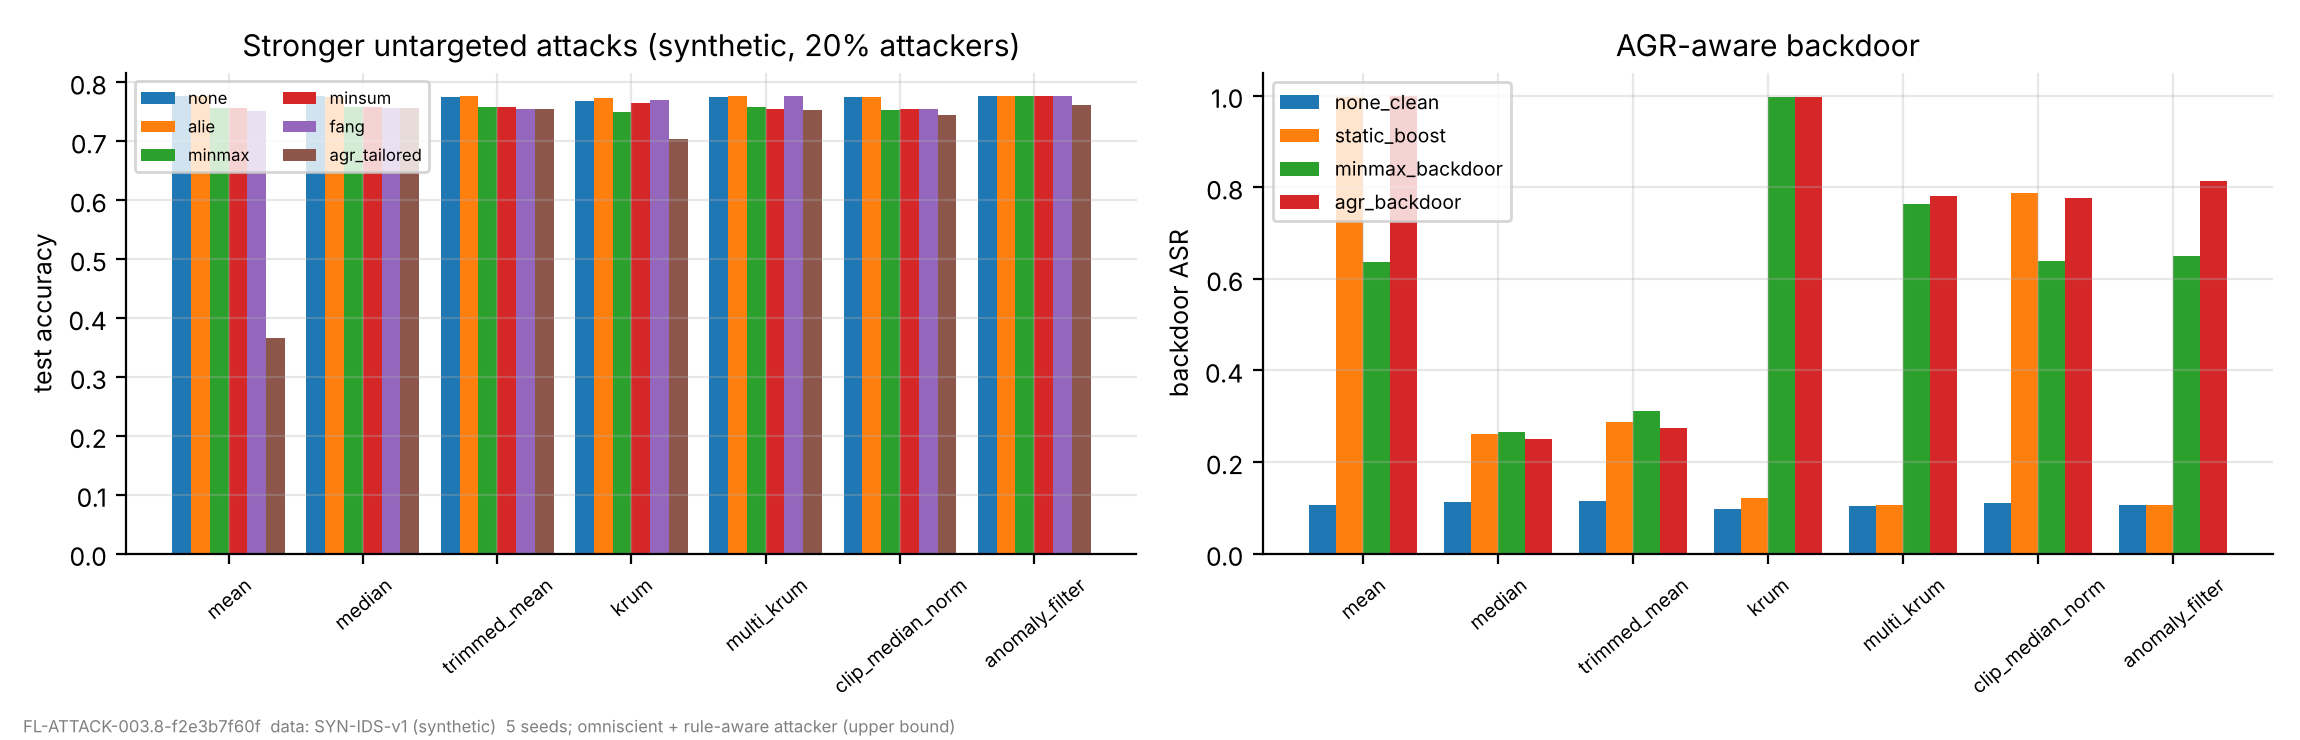

In [10]:
show_fig('task_3_8_stronger_adaptive.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

The attacker is an upper bound (omniscient, rule-aware, unconstrained gamma in the tailored candidates); a better optimiser could be stronger still.

In [11]:
d = pd.read_csv(RES / 'task_3_8_untargeted_summary.csv'); print(d[d.dataset=='syn'].pivot_table(index='defense', columns='attack', values='acc').round(3).to_string()); b = pd.read_csv(RES / 'task_3_8_backdoor_summary.csv'); print(b.pivot_table(index='defense', columns='attack', values='asr').round(3).to_string())

attack            agr_tailored   alie   fang  minmax  minsum   none
defense                                                            
anomaly_filter           0.761  0.777  0.776   0.777   0.777  0.777
clip_median_norm         0.744  0.775  0.754   0.753   0.755  0.774
krum                     0.704  0.774  0.770   0.749   0.765  0.768
mean                     0.366  0.777  0.750   0.756   0.757  0.777
median                   0.756  0.775  0.756   0.758   0.758  0.777
multi_krum               0.753  0.776  0.777   0.757   0.755  0.775
trimmed_mean             0.755  0.776  0.755   0.758   0.758  0.776
attack            agr_backdoor  minmax_backdoor  none_clean  static_boost
defense                                                                  
anomaly_filter           0.814            0.649       0.107         0.106
clip_median_norm         0.776            0.639       0.111         0.788
krum                     0.997            0.996       0.097         0.120
mean              

## 16. Limitations
- Fixed candidate set; no gradient-based or loss-aware attacker.
- Synthetic and one real table only.
- Full participation required (row index = client id).
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`shejwalkar2021`, `fang2020`, `baruch2019`, `blanchard2017`, `yin2018` — details in `docs/fl_attack_003/references.md`.